# Chapitre 10 - Exercices 10.1 à 10.5

Ce notebook traite les cinq premiers exercices du chapitre 10, centrés sur une
machine, le stockage distribué et le modèle MapReduce :

- **10.1** : table de hachage ou tri ? Ordres de grandeur d'une analyse de journal
  trop grosse pour la mémoire (calcul) ;
- **10.2** : régler la fusion d'un tri externe, entre nombre de passes et accès
  disque (calcul et mini-lab) ;
- **10.3** : dimensionner un système de fichiers distribué : métadonnées, réplication
  ou codes d'effacement, trafic de réparation (calcul) ;
- **10.4** : préemption et taille des tâches : trouver la granularité optimale (calcul
  et simulation) ;
- **10.5** : le combineur, et pourquoi il ne marche pas pour une moyenne (mini-lab).

In [1]:
import math
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 10.1 : table de hachage ou tri ?

**Énoncé.** Un site produit chaque jour 2 To de journaux d'accès (lignes de 250 octets en
moyenne). On veut compter les requêtes par couple (adresse IP, URL). Une étude préalable
estime à 1,5 milliard le nombre de couples distincts. On dispose d'une machine de 64 Go
de RAM, avec un disque qui lit et écrit séquentiellement à 500 Mo/s.

1. Combien de lignes le journal contient-il ? Quelle mémoire faudrait-il à une table de
   hachage (on compte 100 octets par entrée, clé et compteur compris, dans un langage
   compilé) ? Tient-elle en mémoire ?
2. On procède comme le pipeline Unix : on extrait les clés (60 octets par clé en
   moyenne), on les trie par tri externe avec 50 Go de tampon et une fusion à 10 voies,
   puis on compte les répétitions au fil de la fusion finale. Combien de segments, de
   passes de fusion ? Quel volume lit-on et écrit-on, et combien de temps cela prend-il
   au minimum ?
3. Même question si l'on compte seulement par URL (200 000 URL distinctes).
4. Pourquoi le tri externe reste-t-il possible quelle que soit la taille des données,
   alors que la table de hachage échoue brutalement ?

**Rappels.** Ensemble de travail d'une agrégation par hachage, tri externe (segments
triés puis fusion à $k$ voies, $\lceil \log_k(N/M) \rceil$ passes) : cours 1, section 4
(section *Sorting versus in-memory aggregation*).

**Solution.**

*1.* $2 \cdot 10^{12} / 250 = 8 \cdot 10^9$ lignes. Table de hachage : $1{,}5 \cdot 10^9
\times 100 = 150$ Go, plus du double de la RAM. Elle ne tient pas : le système se met à
paginer (accès aléatoires sur disque, des millions de fois plus lents) puis manque de
mémoire.

*2.* Clés extraites : $8 \cdot 10^9 \times 60 = 480$ Go. Segments : $480/50 = 10$. Avec
une fusion à 10 voies, **une seule** passe de fusion suffit, et elle peut alimenter
directement le comptage. Volumes : lecture du journal (2 To), écriture des segments
(480 Go), relecture des segments (480 Go), soit 2,96 To de transferts séquentiels :
$2{,}96 \cdot 10^{12} / 5 \cdot 10^8 \approx 5\,900$ s, environ **1 h 40** (si le
processeur suit). La lecture initiale représente les deux tiers du temps.

*3.* Par URL : $200\,000 \times 100$ octets = 20 Mo. La table tient largement : une seule
lecture du journal, environ 4 000 s, limitée par le disque. Le tri n'apporte rien.

*4.* Le tri externe n'a besoin en mémoire que d'un paquet à trier et d'un tampon par
segment fusionné ; si les données grossissent, il ajoute des segments, puis des passes,
et son coût croît en $N \log(N/M)$. La table de hachage a besoin d'une entrée par clé
distincte **en accès aléatoire** : au-delà de la RAM, rien ne va plus.

In [2]:
lignes = 2e12 / 250
cles = 8e9 * 60
segments = math.ceil(cles / 50e9)
passes = B.merge_passes(segments, 10)
octets = 2e12 + cles * (1 + passes)          # lecture du journal + écriture des segments + relecture à chaque passe
pd.DataFrame({"valeur": [fmt(lignes), f"{1.5e9 * 100 / 1e9:.0f} Go", f"{cles / 1e9:.0f} Go", segments, passes,
                         f"{octets / 1e12:.2f} To", f"{octets / 5e8 / 3600:.2f} h", f"{2e12 / 5e8 / 3600:.2f} h"]},
             index=["lignes", "table de hachage (IP, URL)", "clés extraites", "segments", "passes de fusion",
                    "volume transféré", "durée minimale (tri)", "durée minimale (hachage par URL)"])

,valeur
lignes,8 000 000 000
"table de hachage (IP, URL)",150 Go
clés extraites,480 Go
segments,10
passes de fusion,1
volume transféré,2.96 To
durée minimale (tri),1.64 h
durée minimale (hachage par URL),1.11 h


**Vérification expérimentale** à échelle réduite : trions $N$ clés avec une mémoire de
$M$ éléments et une fusion à 10 voies, pour des rapports $N/M$ croissants, et comparons
les passes mesurées à la formule.

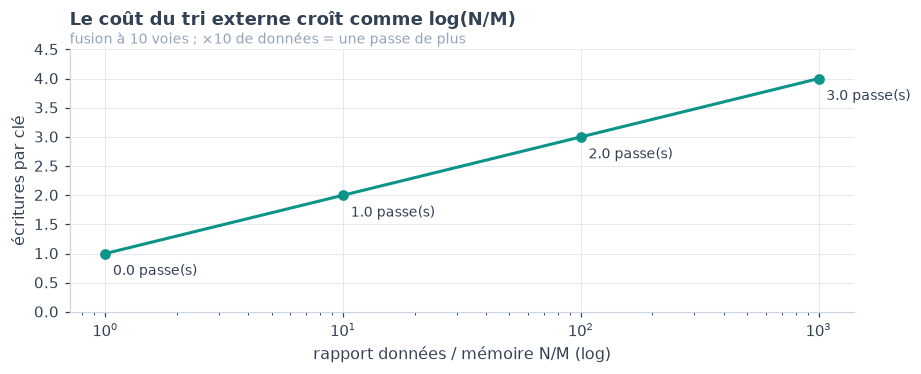

,rapport,segments,passes,formule,ecritures_par_cle
0,1,1,0,0,1.0
1,10,10,1,1,2.0
2,100,100,2,2,3.0
3,1000,1000,3,3,4.0


In [3]:
rng = np.random.default_rng(1)
N = 60_000
data = [f"{a}|{b}" for a, b in zip(rng.integers(0, 10**6, N), rng.integers(0, 10**4, N))]
rows = []
for M in [60_000, 6_000, 600, 60]:
    out, st = B.external_sort(data, max_in_memory=M, fan_in=10)
    assert out == sorted(data)
    rows.append(dict(rapport=N // M, segments=st.n_runs, passes=st.merge_passes, formule=B.merge_passes(st.n_runs, 10),
                     ecritures_par_cle=st.records_written / N))
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.semilogx(R.rapport, R.ecritures_par_cle, "o-", color=TEAL)
for _, r in R.iterrows():
    ax.annotate(f"{r.passes} passe(s)", (r.rapport, r.ecritures_par_cle), (5, -14), textcoords="offset points", fontsize=9)
ax.set_xlabel("rapport données / mémoire N/M (log)"); ax.set_ylabel("écritures par clé")
ax.set_ylim(0, 4.5)
ax.set_title("Le coût du tri externe croît comme log(N/M)")
subtitle(ax, "fusion à 10 voies ; ×10 de données = une passe de plus")
plt.tight_layout(); plt.show()
R

Chaque multiplication par 10 du rapport $N/M$ ajoute exactement une passe, comme le
prévoit $\lceil \log_{10}(N/M) \rceil$.

> **À retenir.** Quand l'ensemble de travail dépasse la RAM, le tri externe prend le
> relais avec un coût logarithmique en $N/M$ ; avec une fusion assez large, une seule
> passe suffit souvent et le temps est dominé par la lecture de l'entrée. Toujours
> estimer le nombre de clés **distinctes** avant de choisir.